In [3]:
import os
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
# Load ảnh đã được mask (KHÔNG qua bước trích xuất đặc trưng)
x_masked = np.load("../Data/Processed/x_resized_masked.npy")  # shape: (21165, 128, 128)
y_labels = np.load("../Data/Processed/y_labels.npy")          # shape: (21165,)

print(f"Shape ảnh mask: {x_masked.shape}")
print(f"Shape nhãn:     {y_labels.shape}")
print(f"Các nhãn có trong dataset: {np.unique(y_labels)}")  
# 0=Normal, 1=COVID, 2=Viral Pneumonia, 3=Lung_Opacity

# Flatten: (21165, 128, 128) → (21165, 16384)
x_flat = x_masked.reshape(len(x_masked), -1).astype(np.float32)
print(f"Shape sau khi flatten: {x_flat.shape}")


Shape ảnh mask: (21165, 128, 128)
Shape nhãn:     (21165,)
Các nhãn có trong dataset: [0 1 2 3]
Shape sau khi flatten: (21165, 16384)


In [5]:
# Chia 80% train, 10% val, 10% test
x_train, x_val_test, y_train, y_val_test = train_test_split(
    x_flat, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)
x_val, x_test, y_val, y_test = train_test_split(
    x_val_test, y_val_test, test_size=0.5, random_state=41, stratify=y_val_test
)

# Chuẩn hóa pixel (quan trọng với SVM, LR, KNN)
scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train)
x_val_sc   = scaler.transform(x_val)
x_test_sc  = scaler.transform(x_test)

print(f"Train:      {x_train_sc.shape}")
print(f"Validation: {x_val_sc.shape}")
print(f"Test:       {x_test_sc.shape}")


Train:      (16932, 16384)
Validation: (2116, 16384)
Test:       (2117, 16384)


In [6]:
import time
import gc
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

# Giải phóng RAM các biến không cần thiết
for var in ['x_masked', 'x_flat', 'x_train', 'x_val', 'x_test', 'x_val_test']:
    if var in globals():
        del globals()[var]
gc.collect()

# Đảm bảo float32 và contiguous array để tối ưu tốc độ
x_train_sc = np.ascontiguousarray(x_train_sc, dtype=np.float32)
x_val_sc   = np.ascontiguousarray(x_val_sc, dtype=np.float32)
x_test_sc  = np.ascontiguousarray(x_test_sc, dtype=np.float32)

CLASS_NAMES = ['Normal', 'COVID', 'Viral Pneumonia', 'Lung_Opacity']

def train_and_evaluate(model, model_name, x_tr, y_tr, x_v, y_v):
    print(f"\n{'='*55}")
    print(f"  Đang huấn luyện: {model_name} ...")
    print(f"{'='*55}")
    t0 = time.time()
    model.fit(x_tr, y_tr)
    train_time = time.time() - t0

    t1 = time.time()
    y_pred = model.predict(x_v)
    pred_time = time.time() - t1

    acc = accuracy_score(y_v, y_pred)
    print(f"Thời gian Train: {train_time:.1f}s | Predict: {pred_time:.1f}s")
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(y_v, y_pred, target_names=CLASS_NAMES))
    return model, acc, y_pred

# 1. Logistic Regression
lr_model, lr_acc, lr_pred = train_and_evaluate(
    LogisticRegression(solver='lbfgs', max_iter=200, tol=1e-3, random_state=42),
    "Logistic Regression",
    x_train_sc, y_train, x_val_sc, y_val
)

# 2. KNN
knn_model, knn_acc, knn_pred = train_and_evaluate(
    KNeighborsClassifier(n_neighbors=5, algorithm='brute', n_jobs=-1),
    "K-Nearest Neighbors (KNN)",
    x_train_sc, y_train, x_val_sc, y_val
)

# 3. SVM (LinearSVC)
svm_model, svm_acc, svm_pred = train_and_evaluate(
    LinearSVC(dual=False, C=1.0, tol=1e-2, max_iter=200, random_state=42),
    "Support Vector Machine (SVM)",
    x_train_sc, y_train, x_val_sc, y_val
)

# Tổng kết
print("\n========== TỔNG KẾT VALIDATION ACCURACY ==========")
results = {"Logistic Regression": lr_acc, "KNN": knn_acc, "SVM": svm_acc}
for name, acc in results.items():
    print(f"  {name:<25}: {acc:.4f}")

best_name = max(results, key=results.get)
best_model = {"Logistic Regression": lr_model, "KNN": knn_model, "SVM": svm_model}[best_name]
print(f"\n>>> Mô hình tốt nhất trên Validation: {best_name} ({results[best_name]:.4f})")



  Đang huấn luyện: Logistic Regression ...
Thời gian Train: 49.3s | Predict: 0.0s
Validation Accuracy: 0.5482
                 precision    recall  f1-score   support

         Normal       0.67      0.63      0.65      1019
          COVID       0.31      0.33      0.32       361
Viral Pneumonia       0.68      0.70      0.69       135
   Lung_Opacity       0.48      0.51      0.50       601

       accuracy                           0.55      2116
      macro avg       0.53      0.54      0.54      2116
   weighted avg       0.56      0.55      0.55      2116


  Đang huấn luyện: K-Nearest Neighbors (KNN) ...
Thời gian Train: 0.1s | Predict: 8.9s
Validation Accuracy: 0.6432
                 precision    recall  f1-score   support

         Normal       0.66      0.87      0.75      1019
          COVID       0.37      0.24      0.29       361
Viral Pneumonia       0.86      0.73      0.79       135
   Lung_Opacity       0.69      0.49      0.57       601

       accuracy            

C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Thời gian Train: 2145.0s | Predict: 0.1s
Validation Accuracy: 0.5378
                 precision    recall  f1-score   support

         Normal       0.66      0.62      0.64      1019
          COVID       0.30      0.30      0.30       361
Viral Pneumonia       0.60      0.53      0.56       135
   Lung_Opacity       0.48      0.53      0.51       601

       accuracy                           0.54      2116
      macro avg       0.51      0.50      0.50      2116
   weighted avg       0.54      0.54      0.54      2116


========== TỔNG KẾT VALIDATION ACCURACY ==========
  Logistic Regression      : 0.5482
  KNN                      : 0.6432
  SVM                      : 0.5378

>>> Mô hình tốt nhất trên Validation: KNN (0.6432)



========== KẾT QUẢ TRÊN TẬP TEST (KNN) ==========
Test Accuracy: 0.6467
                 precision    recall  f1-score   support

         Normal       0.65      0.90      0.76      1019
          COVID       0.39      0.22      0.28       362
Viral Pneumonia       0.88      0.63      0.73       134
   Lung_Opacity       0.70      0.48      0.57       602

       accuracy                           0.65      2117
      macro avg       0.66      0.56      0.59      2117
   weighted avg       0.64      0.65      0.62      2117



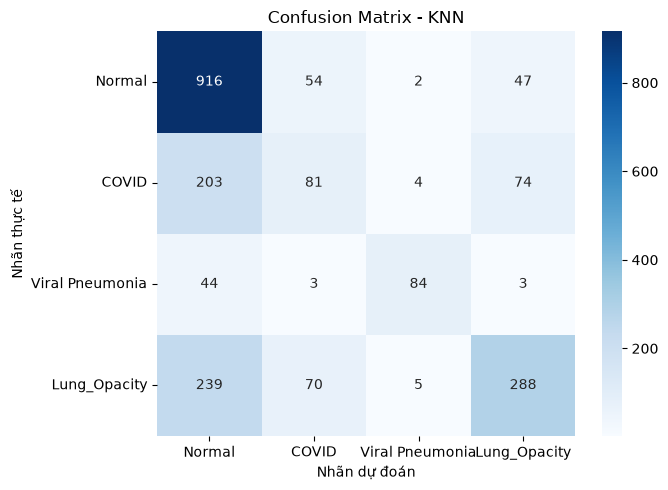


 Đã lưu mô hình 'KNN' và scaler thành công vào ../Data/Models/


In [8]:
# Đảm bảo thư mục lưu trữ đã tồn tại
os.makedirs("../Data/Models", exist_ok=True)

# Đánh giá mô hình tốt nhất trên tập Test
y_test_pred = best_model.predict(x_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"\n========== KẾT QUẢ TRÊN TẬP TEST ({best_name}) ==========")
print(f"Test Accuracy: {test_acc:.4f}")
print(classification_report(y_test, y_test_pred, target_names=CLASS_NAMES))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion Matrix - {best_name}")
plt.ylabel("Nhãn thực tế")
plt.xlabel("Nhãn dự đoán")
plt.tight_layout()
plt.savefig("../Data/Models/confusion_matrix_baseline.png", dpi=150)
plt.show()

# Lưu mô hình tốt nhất và scaler
joblib.dump(best_model, f"../Data/Models/baseline_{best_name.replace(' ', '_')}.pkl")
joblib.dump(scaler,     "../Data/Models/scaler_mask.pkl")
print(f"\n Đã lưu mô hình '{best_name}' và scaler thành công vào ../Data/Models/")
